## Project 2 on Machine Learning: classification and regression, writing our own neural network code

**Data Analysis and Machine Learning FYS-STK3155/FYS4155, University of Oslo, fall 2026**

**Deadline: November 6 (midnight), 2026.** Published October 6, 2026.

This notebook is the Jupyter version of the project text (`Project2.pdf`). The
code cells are *starting points*, not solutions: they set up the Runge data of
project 1 and show how to fetch the MNIST data for part e). Everything else is
yours to write.


### What you should take away from this project

Beyond the figures and tables in your report, these are the insights we want you to be able to state, explain and defend after working through the project. Use them as a checklist when you write your conclusions.

1.  **A neural network replaces hand-made features by learned ones.** In project 1 the design matrix contained powers of $x$ that you chose. A network takes the raw input and learns its own features in the hidden layers; the universal approximation theorem (Section [8.4](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-universal-approximation-theorem)) tells you that this is possible, not that it is easy.

2.  **Backpropagation is reverse-mode automatic differentiation applied to a layered function.** The four equations of Section [8.8.4](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-four-equations-of-backpropagation) are nothing but the chain rule organized so that one forward and one backward sweep give the gradient with respect to every weight and bias, at a cost of roughly two forward passes, independently of the number of parameters. You should be able to derive them and to check your implementation against `jax.grad`.

3.  **The output activation and the cost function come in matched pairs.** Linear output with the MSE, sigmoid with the binary cross entropy and softmax with the multiclass cross entropy all give the same output error $\boldsymbol{\delta}^L=\boldsymbol{a}^L-\boldsymbol{y}$ (up to the normalization). Mixing the pairs (for instance a sigmoid output with the MSE) gives tiny gradients exactly where the network is confidently wrong.

4.  **The optimizer does not care where the gradient comes from.** Plain gradient descent, stochastic gradient descent, RMSprop and Adam from project 1 carry over unchanged; what changes is that the cost function is no longer convex, so the learning rate, the initialization and the minibatch size now decide whether you converge at all, and to which minimum.

5.  **Initialization and scaling are not details.** Unscaled inputs or weights of the wrong size saturate the sigmoid, and the gradient vanishes (Sections [8.9](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#vanishing-and-exploding-gradients) and [8.10](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#weight-initialisation)). Standardized inputs, Xavier or He initialization and the ReLU family exist precisely to keep the gradients alive.

6.  **Hyperparameters must be searched systematically, and on validation data.** The learning rate $\gamma$, the penalty $\lambda$, the depth, the width and the activation function interact. A grid of two parameters at a time, shown as a heat map, is far more informative than a handful of hand-picked runs, and the test set is used only once, at the end.

7.  **Overfitting looks the same as in project 1.** A growing gap between training and test error as the number of parameters grows is the same bias-variance story as for the polynomial degree, and the $L_1$ and $L_2$ penalties play the same role as in Ridge and Lasso regression; early stopping is a form of regularization that costs nothing.

8.  **More flexible is not automatically better.** For a smooth one-dimensional function, OLS with a well-chosen polynomial degree is a closed-form, cheap and hard-to-beat benchmark. The neural network earns its cost only when the features are not known in advance, as for the pixels of MNIST. Your report should say when each method is the right tool.

9.  **A number is meaningless without a baseline.** An accuracy of 97% on MNIST is good only if you know that guessing gives 10%, that logistic regression on raw pixels gives roughly 92% and that convolutional networks reach above 99%. A confusion matrix tells you which errors remain; the accuracy alone does not.

10. **A code you cannot verify is a code you cannot trust.** Gradient checks against automatic differentiation, recovering the closed-form OLS solution with a linear network, and comparing with Scikit-Learn or PyTorch are the tests that turn your implementation into a result you can defend. Seeds and documented hyperparameters make the result reproducible.

We will start with a regression problem and we will reuse our codes on gradient descent methods from project 1.


## defining functions needed for full project, imports

In [26]:
#imports
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.datasets import load_digits
from sklearn.metrics import (
    confusion_matrix as sk_confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report as sk_classification_report,
    roc_curve as sk_roc_curve,
    roc_auc_score,
    RocCurveDisplay
)
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.linear_model import LogisticRegression
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor

In [27]:
def sigmoid(z):
    return 1 / (1 + jnp.exp(-z))

def sigmoid_derivative(z):
    p = sigmoid(z)
    return p*(1.0-p)

    
def ReLU(z):
    return jnp.where(z > 0, z, 0.0)

def relu_derivative(z):
    return jnp.where(z > 0, 1.0, 0.0)

def leaky_relu(z, alpha=0.01):
    return jnp.where(z > 0, z, alpha * z)

def leaky_relu_derivative(z, alpha=0.01):
    return jnp.where(z > 0, 1.0, alpha)

def linear(z):
    return z

def linear_derivative(z):
    return jnp.ones_like(z)

def softmax(z):
    shifted = z - jnp.max(z, axis=1, keepdims=True)
    e = jnp.exp(shifted)
    return e / jnp.sum(e, axis=1, keepdims=True)

# define cost functions
def mse(predict, target):
    return jnp.mean((predict - target) ** 2)


def mse_gradient(prediction, target):
    return 2 * (prediction - target) / target.size

# L1 regularisation
def l1_reg(W):
    return jnp.sum(jnp.abs(W))

def l1_reg_gradient(W):
    return jnp.sign(W)


# L2 regularisation
def l2_reg(W):
    return jnp.sum(W ** 2)

def l2_reg_gradient(W):
    return 2 * W

## solution part b: build network and fix optimizer (done)

### Part b): Writing your own neural network code


Your aim now, and this is the central part of this project, is to write your own FFNN code implementing the back propagation algorithm discussed in the lecture material of week 41 (see <https://github.com/EducationalMaterialUiO/MachineLearningUiO/tree/main/doc/WeeklyMaterial/week41>) and week 42 (see <https://github.com/EducationalMaterialUiO/MachineLearningUiO/tree/main/doc/WeeklyMaterial/week42>), and in Section [8.8](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#backpropagation) of the lecture notes. The notation and the feed-forward pass are set up in Section [8.5](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#notation-and-the-feed-forward-pass), the general dense-layer case and the four equations of backpropagation in Sections [8.8.3](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-general-case-dense-layers) and [8.8.4](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-four-equations-of-backpropagation), and the full algorithm in Section [8.8.5](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-algorithm). A complete network from scratch, including a check of the gradient against automatic differentiation, is discussed in Section [8.13](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#a-neural-network-from-scratch). The exercises of week 41 (`exercisesweek41.ipynb`) give you a template for the code: samples are stored in the rows of the input, the weight matrix of a layer has shape (inputs, outputs), and the feed-forward step of a layer reads `a @ W + b`.

We will focus on a regression problem first, using the one-dimensional Runge function

$$
f(x) = \frac{1}{1+25x^2},
$$

from project 1.

Use only the mean-squared error as cost function (no regularization terms) and write an FFNN code for a regression problem with a flexible number of hidden layers and nodes using only the Sigmoid function as activation function for the hidden layers. Initialize the weights using a normal distribution (see Section [8.10](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#weight-initialisation) for how the width of that distribution should depend on the number of inputs of a layer). How would you initialize the biases? And which activation function would you select for the final output layer? And how would you set up your design/feature matrix? Hint: does it have to represent a polynomial approximation as you did in project 1?

Train your network and compare the results with those from your OLS regression code from project 1 using the one-dimensional Runge function. When comparing your neural network code with the OLS results from project 1, use the same data sets which gave you the best MSE score. Moreover, use the polynomial order from project 1 that gave you the best result. Compare these results with your neural network with one and two hidden layers using $50$ and $100$ hidden nodes, respectively.

Comment your results and give a critical discussion of the results obtained with the OLS code from project 1 and your own neural network code. Make an analysis of the learning rates employed to find the optimal MSE score. Test both stochastic gradient descent with RMSprop and Adam and plain gradient descent with different learning rates.

You should, as you did in project 1, scale your data (Section 3.13 of the lecture notes).

(100, 1) (100,)


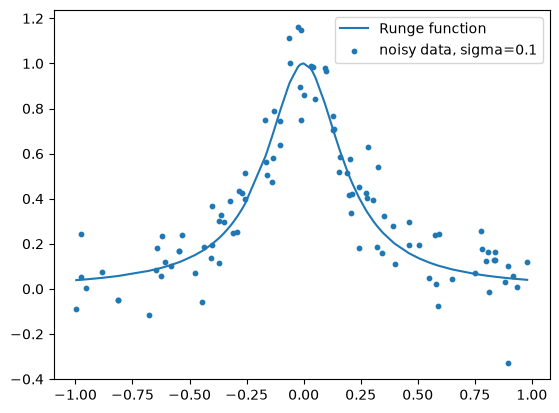

In [28]:
# The data of project 1, as a starting point for part b)
import numpy as np
import matplotlib.pyplot as plt

def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)# fix the seed for reproducible results
n = 100
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1
y = runge(x) + rng.normal(0.0, sigma, n)

# For the network the input is the raw x (one feature), samples in rows
X = x.reshape(-1, 1)
print(X.shape, y.shape)
plt.plot(x, runge(x), label="Runge function")
plt.scatter(x, y, s=10, label=f"noisy data, sigma={sigma}")
plt.legend(); plt.show()


In [29]:
# functions to create NN
def create_layers_batch(network_input_size, layer_output_sizes, rng):
    """week42tuesday.ipynb
     Network initialization : we Initialize weights from a normal distribution and biases b =  0.01
    """
    layers = []
    input_size = network_input_size
    for output_size in layer_output_sizes:
        W = jnp.asarray(rng.normal(0, 1 / np.sqrt(input_size), (input_size, output_size)))
        b = jnp.zeros(output_size) + 0.01 # B = 0.01
        layers.append((W, b))
        input_size = output_size
    return layers


def feed_forward_batch(inputs, layers, activation_funcs):
    """ from week42 tuesday """
    a = inputs
    for (W, b), activation in zip(layers, activation_funcs):
        a = activation(a @ W + b)
    return a


def feed_forward_saver_batch(inputs, layers, activation_funcs):
    """ from week42 tuesday: does forward propagation while saving  values for backpropagation.."""
    layer_inputs, zs = [], []
    a = inputs
    for (W, b), activation in zip(layers, activation_funcs):
        layer_inputs.append(a)
        z = a @ W + b
        a = activation(z)
        zs.append(z)
    return layer_inputs, zs, a

def backpropagation_batch(inputs, layers, activation_funcs, targets, activation_ders, cost_gradient=mse_gradient, reg_gradients=(), reg_strengths=()):
    """from week42tuesday with added possibility of using regularization by providing gradient and lambdas."""
    layer_inputs, zs, prediction = feed_forward_saver_batch(inputs, layers, activation_funcs)
    layer_grads = [None] * len(layers)

    for i in reversed(range(len(layers))):
        if i == len(layers) - 1:
            dC_da = cost_gradient(prediction, targets)
            dC_dz = dC_da * activation_ders[i](zs[i])
        else:
            W_next, _ = layers[i + 1]
            dC_da = dC_dz @ W_next.T
            dC_dz = dC_da * activation_ders[i](zs[i])

        dC_dW = layer_inputs[i].T @ dC_dz
        dC_db = jnp.sum(dC_dz, axis=0)

        # add regularisation gradients (this does nothing if reg_gradients and reg_strengths are empty -> normal MSE)
        W, b = layers[i]
        for reg_gradient, strength in zip(reg_gradients, reg_strengths):
            dC_dW += strength * reg_gradient(W)

        layer_grads[i] = (dC_dW, dC_db)
    return layer_grads

In [30]:
# functions for gradient descent/ batching
def optimiser_step(method, theta, gradient, state, step, rate):
    """
    from project 1,parameter updates using GD, RMSprop, and Adam.
    """
    if method == 'gd':
        return theta - rate * gradient, state
    if method == 'rmsprop':
        state['r'] = 0.99 * state.get('r', 0.0) + 0.01 * gradient**2
        return theta - rate * gradient / (jnp.sqrt(state['r']) + 1e-8), state
    if method == 'adam':
        state['m'] = 0.9 * state.get('m', 0.0) + 0.1 * gradient
        state['r'] = 0.999 * state.get('r', 0.0) + 0.001 * gradient**2
        m_hat = state['m'] / (1.0 - 0.9**step)
        r_hat = state['r'] / (1.0 - 0.999**step)
        return theta - rate * m_hat / (jnp.sqrt(r_hat) + 1e-8), state
    raise ValueError('Use gd, rmsprop or adam.')


def make_batches(n, batch_size, rng):# also from project 1
    indices = rng.permutation(n)
    return [indices[i:i + batch_size] for i in range(0, n, batch_size)]

In [31]:
# funciton to train network, including option to use different regularizations
def train_network(layers, X, y, 
                activation_funcs, 
                activation_ders, 
                optimizer, 
                rate, 
                epochs, 
                cost_func=mse,
                cost_gradient=mse_gradient,
                reg_funcs=(),
                reg_gradients=(),
                reg_strengths=(),
                X_validation=None, 
                y_validation=None,
                batch_size=32, 
                seed=2026
                ):

    # initialize arrays and parameters
    X, y = jnp.asarray(X), jnp.asarray(y)
    if X_validation is not None:
        X_validation, y_validation = jnp.asarray(X_validation), jnp.asarray(y_validation)
    rng = np.random.default_rng(seed)
    states = [[{}, {}] for _ in layers]
    history = [] # Store training and validation losses during training
    best_validation = np.inf
    best_layers = [(W.copy(), b.copy()) for W, b in layers]  # Keep a copy of the initial network parameters in case no validation improvement occurs
    best_epoch = 0
    step = 0

    # loop over epochs
    for epoch in range(1, epochs + 1):
        # create batches for the current epoch (full dataset for gd, smaller batches (batch_size) for other methods)
        batches = [np.arange(len(X))] if optimizer == 'gd' else make_batches(len(X), batch_size, rng)

        # loop over batches in the current epoch
        for indices in batches:
            gradients = backpropagation_batch(X[indices], layers, activation_funcs, y[indices], 
                                            activation_ders, 
                                            cost_gradient,
                                            reg_gradients,
                                            reg_strengths
                                            )
            step += 1

            # update weights and biases in every layer using the selected optimizer, then save
            for i, ((W, b), (dW, db)) in enumerate(zip(layers, gradients)):
                W, states[i][0] = optimiser_step(optimizer, W, dW, states[i][0], step, rate)
                b, states[i][1] = optimiser_step(optimizer, b, db, states[i][1], step, rate)

                layers[i] = (W, b)

        # calculate loss every 20 epochs
        if epoch % 20 == 0 or epoch == epochs:
            # predictions and loss at current parameters
            training_prediction = feed_forward_batch(X, layers, activation_funcs)
            training_loss = cost_func(training_prediction, y)

            # add regularization penalties to training loss
            for reg_func, strength in zip(reg_funcs, reg_strengths):
                for W, b in layers:
                    training_loss += strength * reg_func(W)

            training_loss = float(training_loss)

            # track loss
            if X_validation is None:
                # only for training if no validation dataset is given
                history.append((epoch, training_loss))
                best_layers = [(W.copy(), b.copy()) for W, b in layers]
                best_epoch = epoch

            else:
                # for both training and validation if validation dataset is given

                # calculate predictions and loss for the validation dataset, add regularization
                validation_prediction = feed_forward_batch(X_validation, layers, activation_funcs)
                validation_loss = cost_func(validation_prediction, y_validation)
                for reg_func, strength in zip(reg_funcs, reg_strengths):
                    for W, b in layers:
                        validation_loss += strength * reg_func(W)

                validation_loss = float(validation_loss)

                # store
                history.append((epoch, training_loss, validation_loss))

                # check whether the current validation loss is lower than the best one so far
                if validation_loss < best_validation:
                    best_validation = validation_loss
                    best_layers = [(W.copy(), b.copy()) for W, b in layers]
                    best_epoch = epoch

    return best_layers, np.asarray(history), best_epoch

In [32]:
def prepare_runge_data(n):
    rng = np.random.default_rng(2026)
    x = np.sort(rng.uniform(-1.0, 1.0, n))[:, None]
    y = runge(x) + rng.normal(0.0, 0.1, (n, 1))
    training, test = train_test_split(np.arange(n), test_size=0.2, random_state=2026)
    fitting, validation = train_test_split(training, test_size=0.25, random_state=2026)
    x_scaler = StandardScaler().fit(x[fitting])
    y_scaler = StandardScaler().fit(y[fitting])
    return dict(n=n, x=x, y=y, training=training, test=test, fitting=fitting,
                validation=validation, x_scaler=x_scaler, y_scaler=y_scaler,
                X_scaled=x_scaler.transform(x), y_scaled=y_scaler.transform(y))

In [33]:
def ols_predictions(x_train, y_train, x_evaluate, degree):# from project 1

    x_train = np.asarray(x_train).ravel()
    x_evaluate = np.asarray(x_evaluate).ravel()
    raw_train = np.column_stack([x_train**power for power in range(1, degree + 1)])
    raw_evaluate = np.column_stack([x_evaluate**power for power in range(1, degree + 1)])
    scaler = StandardScaler().fit(raw_train)
    design = scaler.transform(raw_train)
    y_mean = y_train.mean()
    beta = np.linalg.lstsq(design, y_train.ravel() - y_mean, rcond=None)[0]
    return (scaler.transform(raw_evaluate) @ beta + y_mean)[:, None]

In [34]:
def fit_configuration(data, widths, activation, activation_derivative,
                      optimizer, rate, epochs=1000,
                      cost_func=mse,
                      cost_gradient=mse_gradient,
                      reg_funcs=(),
                      reg_gradients=(),
                      reg_strengths=()):

    # create network
    layers = create_layers_batch(
        1, list(widths) + [1], np.random.default_rng(2026)
    )

    functions = [activation] * len(widths) + [linear]
    derivatives = [activation_derivative] * len(widths) + [linear_derivative]
    fitting, validation = data['fitting'], data['validation']

    # train network
    layers, history, best_epoch = train_network(
        layers=layers,
        X=data['X_scaled'][fitting],
        y=data['y_scaled'][fitting],
        activation_funcs=functions,
        activation_ders=derivatives,
        optimizer=optimizer,
        rate=rate,
        epochs=epochs,
        cost_func=cost_func,
        cost_gradient=cost_gradient,
        reg_funcs=reg_funcs,
        reg_gradients=reg_gradients,
        reg_strengths=reg_strengths,
        X_validation=data['X_scaled'][validation],
        y_validation=data['y_scaled'][validation]
    )

    # predictions for fitting data
    fitting_prediction = data['y_scaler'].inverse_transform(
        feed_forward_batch(data['X_scaled'][fitting], layers, functions)
    )

    # predictions for validation data
    validation_prediction = data['y_scaler'].inverse_transform(
        feed_forward_batch(data['X_scaled'][validation], layers, functions)
    )

    return dict(
        n=data['n'],
        widths=widths,
        activation=activation.__name__,
        optimizer=optimizer,
        rate=rate,
        epoch=best_epoch,
        layers=layers,
        functions=functions,
        derivatives=derivatives,
        history=history,
        fitting_mse=float(mse(fitting_prediction, data['y'][fitting])),
        validation_mse=float(mse(validation_prediction, data['y'][validation]))
    )

**fit_configuration** combines the functions :  **create_layers_batch, train_network, feed_forward_batch, and mse** to train and evaluate one neural network architecture with a chosen optimizer and learning rate. It selects the epoch with the lowest validation MSE and calculates fitting and validation MSE in the original target units.



In [35]:
def refit_for_test(data, selected):
    training, test = data['training'], data['test']
    x_scaler = StandardScaler().fit(data['x'][training])
    y_scaler = StandardScaler().fit(data['y'][training])
    layers = create_layers_batch(1, list(selected['widths']) + [1], np.random.default_rng(2026))
    layers, _, _ = train_network(layers, x_scaler.transform(data['x'][training]),
        y_scaler.transform(data['y'][training]), selected['functions'], selected['derivatives'],
        selected['optimizer'], selected['rate'], selected['epoch'])
    prediction = y_scaler.inverse_transform(feed_forward_batch(
        x_scaler.transform(data['x'][test]), layers, selected['functions']))
    return dict(layers=layers, x_scaler=x_scaler, y_scaler=y_scaler,
                test_mse=float(mse(prediction, data['y'][test])))

**refit_for_test**  use **create_layers_batch**, **train_network**, **feed_forward_batch**, and **mse** to train agian the (architecture , optimizer , learning rate, number of epochs, activation function) on the original 80% training portion for the choosen number of epochs and it evaluates them on the 20% test set and reports the test MSE for comparison with OLS.

The architectures are  [50](one hidden layer has 50 neurons) and [100, 100] (two hidden layers, each one  has 100 neurons). 
The hidden layers use sigmoid. We test GD rates 0.001, 0.01, 0.1 and RMSprop/Adam rates 0.0003, 0.003, 0.03. The experiment uses 1000 epochs, minibatches of 32 for RMSprop/Adam and seed 2026.


These values are  a matter of choice for the  comparison

#### -> due to Rajis results of this part (see his notebook), we can fix Adam as optimizer from here on. The learning rate $\gamma = 0.03$ was the largest out of the ones we tried, therefore it will need another sweep closer to this value to determine what value it should really take.

## solution part c: fix activation function and architecture (done)

### Part c): Testing different activation functions and depths of the neural network

You should also test different activation functions for the hidden layers. Try out the Sigmoid, the RELU and the Leaky RELU functions and discuss your results (Section [8.6.4](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#which-activation-should-we-use) of the lecture notes discusses which activation to use, and Section [8.9](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#vanishing-and-exploding-gradients) why the sigmoid makes the gradients vanish in deep networks). Test your results as functions of the number of hidden layers and nodes. Do you see signs of overfitting? It is optional in this project to perform a bias-variance trade-off analysis.


We use the 100-observation dataset from Part (b) and test three activation functions: Sigmoid, ReLU and Leaky ReLU.

We compare four network architectures:

[50]: One hidden layer with 50 nodes for  Sigmoid, ReLU , Leaky ReLU

[100]: One hidden layer with 100 nodes for Sigmoid, ReLU , Leaky ReLU

[50, 50]: Two hidden layers with 50 nodes each for Sigmoid, ReLU , Leaky ReLU

[100, 100]: Two hidden layers with 100 nodes each for Sigmoid, ReLU , Leaky ReLU



we keep these settings fixed:

Optimizer: Adam (see previous exercise)

Learning rate: $\gamma \in logspace\{0.003, 0.3\}$

Epochs: 1000

Batch size: 32

Random seed: 2026

We also use  the same  weight and bias initialization from Part (b), with a linear output layer and MSE without regularization.

We use the same fitting and validation split from Part (b)(60% training , 20% validation,20% test ).

For each configuration, we record the fitting and validation MSE at the epoch with the lowest validation MSE.

We also plot fitting and validation MSE over training 


#### --> this analysis in Rajis part (see his notebook) suggests we use ReLU as activation function as this gives the most steady results. Different values for $\gamma$ will still be tried in cross validation in part d). Architecture is best at (50,50) or (100,100), but (100,100) has a large difference between training MSE and test MSE, pointing towards overfitting. We choose (50,50) from here on.

## solution part d) fixing $\gamma$ and $\lambda$ using CV + comparison to Ridge/ Lasso (TODO)

### Part d): Testing different norms

Finally, still using the one-dimensional Runge function, add now the hyperparameters $\lambda$ with the $L_2$ and $L_1$ norms (Section [8.12](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#regularisation-and-hyperparameters) of the lecture notes). Find the optimal results for the hyperparameters $\lambda$ and the learning rates $\gamma$ and neural network architecture and compare the $L_2$ results with Ridge regression from project 1 and the $L_1$ results with the Lasso calculations of project 1. Use again the same data sets and the best results from project 1 in your comparisons.


From exercisesweek44: In this week's exercises and in
Project 2 you are asked to cross-validate the **learning rate $\gamma$ and
the penalty $\lambda$ in front of the $L_2$ or $L_1$ norm**. Cross-validating
the network parameters — the depth, the number of nodes, the activation
function — and the number of epochs is **optional**, both here and in
Project 2

#### Cross-validation wrapper from week 44

In [36]:
def identity(z):
    return z

def identity_derivative(z):
    return jnp.ones_like(z)

ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_derivative),
               "relu": (ReLU, relu_derivative),
               "identity": (identity, identity_derivative)}

PENALTIES = {"l1": (l1_reg, l1_reg_gradient), "l2": (l2_reg, l2_reg_gradient)}


class NeuralNetRegressor(BaseEstimator, RegressorMixin):
    """Project 2 network with the scikit-learn estimator interface.
    penalty=None (default) or lmbd=0 means no regularization."""

    def __init__(self, hidden=(50,), activation="sigmoid", gamma=0.03, lmbd=0.0,
                 penalty=None, epochs=1000, batch_size=10, seed=2026):
        self.hidden = hidden
        self.activation = activation
        self.gamma = gamma
        self.lmbd = lmbd
        self.penalty = penalty
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed

    def _funcs(self):
        f, fp = ACTIVATIONS[self.activation]
        funcs = [f] * len(self.hidden) + [identity]
        ders = [fp] * len(self.hidden) + [identity_derivative]
        return funcs, ders

    def _reg_kwargs(self):
        if self.penalty is None or self.lmbd == 0:
            return {}
        if self.penalty not in PENALTIES:
            raise ValueError(f"penalty must be None, 'l1' or 'l2', got {self.penalty!r}")
        f, g = PENALTIES[self.penalty]
        return dict(reg_funcs=(f,), reg_gradients=(g,), reg_strengths=(self.lmbd,))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        funcs, ders = self._funcs()
        rng = np.random.default_rng(self.seed)
        layers = create_layers_batch(X.shape[1], [*self.hidden, 1], rng)

        self.layers_, self.history_, self.best_epoch_ = train_network(
            layers, X, y, funcs, ders, optimizer="adam", rate=self.gamma,
            epochs=self.epochs, batch_size=self.batch_size, seed=self.seed,
            **self._reg_kwargs())
        
        return self

    def predict(self, X):
        funcs, _ = self._funcs()
        out = feed_forward_batch(jnp.asarray(np.asarray(X, dtype=float)), self.layers_, funcs)
        return np.asarray(out)[:, 0]

def make_model(penalty):
    """
    Builds ONE model object that GridSearchCV can train and test on each fold.
    It bundles three jobs: scale x, train/use our network, un-scale y.
    penalty: None (plain MSE), "l1" or "l2"
    """
    return TransformedTargetRegressor(
        regressor=Pipeline([# MIDDLE layer: runs steps in order
            # standardise x -> (x - mean) / std
            ("scaler", StandardScaler()),
            #network: create_layers_batch / train_network / feed_forward_batch) receives scaled x
            ("net", NeuralNetRegressor(hidden=(50, 50), activation="relu",
                                       penalty=penalty, epochs=400, batch_size=32)),
        ]),
        #scale y
        transformer=StandardScaler(),
    )


In [37]:
#global CV initializations
import pandas as pd 

data = datasets[100]
x_cv = data['x'] #should have shape (100,1)
y_cv = data['y'].ravel() # should have shape (100,)

#the learning rates (gamma) and penalties (lambda) that we will cross validate over
gammas  = np.logspace(np.log10(0.0025), np.log10(0.3), 5)
lambdas = np.logspace(np.log10(0.0001), np.log10(0.1), 5)

#parameter names for the grid
param_grid = {"regressor__net__gamma": gammas, "regressor__net__lmbd": lambdas}

TypeError: 'module' object is not subscriptable

#### CV for MSE cost function on our network

##### 5-fold CV

In [38]:
#call the wrapper
gs_MSE_5fold = GridSearchCV(
    make_model(None),
    {"regressor__net__gamma": gammas},
    scoring="neg_mean_squared_error",
    cv=KFold(5, shuffle=True, random_state=2026), n_jobs=1, refit=True)
gs_MSE_5fold.fit(x_cv, y_cv)

NameError: name 'gammas' is not defined

In [ ]:
res_MSE_5fold = pd.DataFrame(gs_MSE_5fold.cv_results_)
res_MSE_5fold['cv_mse'] = -res_MSE_5fold['mean_test_score']
res_MSE_5fold['cv_std'] = res_MSE_5fold['std_test_score']

print(res_MSE_5fold[['param_regressor__net__gamma', 'cv_mse', 'cv_std']].sort_values('param_regressor__net__gamma').to_string(index=False))
print("Best:", gs_MSE_5fold.best_params_)

 param_regressor__net__gamma   cv_mse   cv_std
                    0.002500 0.018195 0.003111
                    0.008274 0.017177 0.004002
                    0.027386 0.017659 0.004927
                    0.090641 0.017558 0.005629
                    0.300000 0.021463 0.007224
Best: {'regressor__net__gamma': 0.008274377299117182}


##### MSE 10-fold CV

In [ ]:
#call the wrapper
gs_MSE_10fold = GridSearchCV(
    make_model(None),
    {"regressor__net__gamma": gammas},
    scoring="neg_mean_squared_error",
    cv=KFold(10, shuffle=True, random_state=2026), n_jobs=1, refit=True)
gs_MSE_10fold.fit(x_cv, y_cv)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",TransformedTa...ndardScaler())
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'regressor__net__gamma': array([0.0025..., 0.3 ])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=

In [ ]:
res_MSE_10fold = pd.DataFrame(gs_MSE_10fold.cv_results_)
res_MSE_10fold['cv_mse'] = -res_MSE_10fold['mean_test_score']
res_MSE_10fold['cv_std'] = res_MSE_10fold['std_test_score']

print(res_MSE_10fold[['param_regressor__net__gamma', 'cv_mse', 'cv_std']].sort_values('param_regressor__net__gamma').to_string(index=False))
print("Best:", gs_MSE_10fold.best_params_)

 param_regressor__net__gamma   cv_mse   cv_std
                    0.002500 0.017706 0.005350
                    0.008274 0.016932 0.005193
                    0.027386 0.018212 0.005224
                    0.090641 0.018613 0.007104
                    0.300000 0.020535 0.014791
Best: {'regressor__net__gamma': 0.008274377299117182}


#### CV for $L_1$-regularized cost function on our network

For Lasso in project 1, we used:

- polynomial degrees {1, 2, ..., 15}
- NO learning rates
- penalty parameters $\lambda \in \{0.001, 0.01, 0.1\}$

and got the best results for 
- polynomial degree 12
- penalty parameters $\lambda = 0.001$
- optimizer: adam

We use 400 epochs in the following because previous analyses showed convergence of the architecture (sigmoid, (50,50), $\gamma \approx 0.03$) within approx 400 epochs. To save some compute, we thus run the CV at 400 epochs rather than the previous 1000.

$\rightarrow$ Final settings for cross validation:
- learning rates $\gamma \in \{0.025, ..., 0.3\}$ (logspace)
- penalties $\lambda \in \{0, 0.0001, ...., 0.1\}$ (0, then logspace)
- optimizer: Adam
- architecture: sigmoid activation function, (50,50)
- epochs: 400
- CV folds: 5
- cost function: MSE + L1

##### 5-Fold CV

In [ ]:
#call the wrapper
gs_L1_5fold = GridSearchCV(
    make_model("l1"),
    {"regressor__net__gamma": gammas,
     "regressor__net__lmbd":  lambdas},
    scoring="neg_mean_squared_error",
    cv=KFold(5, shuffle=True, random_state=2026), n_jobs=1, refit=True)
gs_L1_5fold.fit(x_cv, y_cv)

# 23 mins on paulas machine

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",TransformedTa...ndardScaler())
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'regressor__net__gamma': array([0.0025..., 0.3 ]), 'regressor__net__lmbd': array([0.0001..., 0.1 ])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for call

In [ ]:
#store results
res_L1_5fold = pd.DataFrame(gs_L1_5fold.cv_results_)
res_L1_5fold['cv_mse'] = -res_L1_5fold['mean_test_score']
res_L1_5fold['cv_std'] = res_L1_5fold['std_test_score']
res_L1_5fold = res_L1_5fold.rename(columns={'param_regressor__net__gamma': 'param_gamma',
                                            'param_regressor__net__lmbd':  'param_lmbd'})
print(res_L1_5fold[['param_gamma', 'param_lmbd', 'cv_mse', 'cv_std']].sort_values('cv_mse').to_string(index=False))
print("Best:", gs_L1_5fold.best_params_)

 param_gamma  param_lmbd   cv_mse   cv_std
    0.090641    0.003162 0.016689 0.003584
    0.027386    0.000100 0.016940 0.004916
    0.008274    0.000100 0.016995 0.003992
    0.027386    0.000562 0.017028 0.005050
    0.002500    0.003162 0.017356 0.002890
    0.027386    0.003162 0.017427 0.003449
    0.090641    0.000562 0.017486 0.005297
    0.008274    0.000562 0.017494 0.003904
    0.090641    0.000100 0.017575 0.004864
    0.002500    0.000562 0.017644 0.003218
    0.008274    0.003162 0.017750 0.003325
    0.002500    0.000100 0.017787 0.002900
    0.002500    0.017783 0.017901 0.002788
    0.008274    0.017783 0.018268 0.003784
    0.027386    0.017783 0.018382 0.003411
    0.090641    0.017783 0.018974 0.002928
    0.300000    0.003162 0.021478 0.006483
    0.300000    0.000562 0.022620 0.004070
    0.300000    0.017783 0.026503 0.007551
    0.008274    0.100000 0.034983 0.008363
    0.090641    0.100000 0.035223 0.008268
    0.002500    0.100000 0.035611 0.008549
    0.02738

##### 10-Fold CV

In [ ]:
#call the wrapper
gs_L1_10fold = GridSearchCV(
    make_model("l1"),
    {"regressor__net__gamma": gammas,
     "regressor__net__lmbd":  lambdas},
    scoring="neg_mean_squared_error",
    cv=KFold(10, shuffle=True, random_state=2026), n_jobs=1, refit=True)
gs_L1_10fold.fit(x_cv, y_cv)

# 34 mins on paulas machine

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",TransformedTa...ndardScaler())
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'regressor__net__gamma': array([0.0025..., 0.3 ]), 'regressor__net__lmbd': array([0.0001..., 0.1 ])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for call

In [ ]:
#store results
res_L1_10fold = pd.DataFrame(gs_L1_10fold.cv_results_)
res_L1_10fold['cv_mse'] = -res_L1_10fold['mean_test_score']
res_L1_10fold['cv_std'] = res_L1_10fold['std_test_score']
res_L1_10fold = res_L1_10fold.rename(columns={'param_regressor__net__gamma': 'param_gamma',
                                            'param_regressor__net__lmbd':  'param_lmbd'})
print(res_L1_10fold[['param_gamma', 'param_lmbd', 'cv_mse', 'cv_std']].sort_values('cv_mse').to_string(index=False))
print("Best:", gs_L1_10fold.best_params_) 

 param_gamma  param_lmbd   cv_mse   cv_std
    0.027386    0.000562 0.016158 0.004279
    0.008274    0.000562 0.016668 0.004723
    0.008274    0.000100 0.016810 0.004355
    0.090641    0.003162 0.016886 0.004000
    0.027386    0.000100 0.017088 0.005056
    0.090641    0.000100 0.017281 0.005334
    0.002500    0.003162 0.017352 0.004835
    0.090641    0.000562 0.017405 0.005199
    0.002500    0.000100 0.017676 0.004457
    0.090641    0.017783 0.017704 0.007021
    0.027386    0.003162 0.017866 0.005154
    0.008274    0.003162 0.017983 0.004867
    0.002500    0.000562 0.018041 0.004455
    0.002500    0.017783 0.018231 0.005964
    0.027386    0.017783 0.018708 0.007383
    0.008274    0.017783 0.018767 0.006377
    0.300000    0.000100 0.019936 0.007457
    0.300000    0.000562 0.021397 0.007997
    0.300000    0.003162 0.029913 0.028425
    0.300000    0.017783 0.031323 0.014774
    0.027386    0.100000 0.035071 0.016077
    0.008274    0.100000 0.035284 0.016278
    0.00250

#### CV for $L_2$-regularized cost function on our network

For Ridge in project 1, we used:

- polynomial degrees {1, 2, ..., 15}
- no learnign rate(s)
- penalty parameters $\lambda \in \{0.001, 0.01, 0.1\}$
- optimizers: Adam, RMSProp, momentum

and got the best results for 
- polynomial degree 12
- penalty parameters $\lambda \sim 1.7 \cdot 10^{-7}$

$\rightarrow$ Final settings for cross validation:
- learning rates $\gamma \in \{0.025, ..., 0.3\}$ (logspace)
- penalties $\lambda \in \{0, 0.0001, ...., 0.1\}$ (0, then logspace)
- optimizer: Adam
- architecture: sigmoid activation function, (50,50)
- epochs: 400
- CV folds: 5
- cost function: MSE + L2

In [ ]:
#call the wrapper
gs_L2_5fold = GridSearchCV(
    make_model("l2"),
    {"regressor__net__gamma": gammas,
     "regressor__net__lmbd":  lambdas},
    scoring="neg_mean_squared_error",
    cv=KFold(5, shuffle=True, random_state=2026), n_jobs=1, refit=True)
gs_L2_5fold.fit(x_cv, y_cv)

# 17 mins on paulas machine

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",TransformedTa...ndardScaler())
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'regressor__net__gamma': array([0.0025..., 0.3 ]), 'regressor__net__lmbd': array([0.0001..., 0.1 ])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for call

In [ ]:
#store results
res_L2_5fold = pd.DataFrame(gs_L2_5fold.cv_results_)
res_L2_5fold['cv_mse'] = -res_L2_5fold['mean_test_score']
res_L2_5fold['cv_std'] = res_L2_5fold['std_test_score']
res_L2_5fold = res_L2_5fold.rename(columns={'param_regressor__net__gamma': 'param_gamma',
                                            'param_regressor__net__lmbd':  'param_lmbd'})
print(res_L2_5fold[['param_gamma', 'param_lmbd', 'cv_mse', 'cv_std']].sort_values('cv_mse').to_string(index=False))
print("Best:", gs_L2_5fold.best_params_)

 param_gamma  param_lmbd   cv_mse   cv_std
    0.027386    0.000100 0.016223 0.004728
    0.027386    0.000562 0.016986 0.004023
    0.008274    0.000100 0.017013 0.003745
    0.027386    0.003162 0.017041 0.003562
    0.090641    0.000100 0.017281 0.005836
    0.008274    0.000562 0.017397 0.003707
    0.090641    0.000562 0.017490 0.004041
    0.002500    0.000100 0.017720 0.003303
    0.002500    0.003162 0.017735 0.003244
    0.008274    0.003162 0.017952 0.004063
    0.090641    0.003162 0.017993 0.003692
    0.002500    0.000562 0.018106 0.002979
    0.002500    0.017783 0.018553 0.003035
    0.027386    0.017783 0.018754 0.003311
    0.008274    0.017783 0.019381 0.003509
    0.300000    0.000562 0.019671 0.003114
    0.300000    0.003162 0.020122 0.004687
    0.090641    0.017783 0.020459 0.003658
    0.300000    0.000100 0.022662 0.008327
    0.002500    0.100000 0.038348 0.009776
    0.008274    0.100000 0.041159 0.010539
    0.027386    0.100000 0.042415 0.011920
    0.09064

##### 10-fold CV

In [ ]:
#call the wrapper
gs_L2_10fold = GridSearchCV(
    make_model("l2"),
    {"regressor__net__gamma": gammas,
     "regressor__net__lmbd":  lambdas},
    scoring="neg_mean_squared_error",
    cv=KFold(10, shuffle=True, random_state=2026), n_jobs=1, refit=True)
gs_L2_10fold.fit(x_cv, y_cv)

# 30 mins on paulas machine

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",TransformedTa...ndardScaler())
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'regressor__net__gamma': array([0.0025..., 0.3 ]), 'regressor__net__lmbd': array([0.0001..., 0.1 ])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for call

In [ ]:
#store results
res_L2_10fold = pd.DataFrame(gs_L2_10fold.cv_results_)
res_L2_10fold['cv_mse'] = -res_L2_10fold['mean_test_score']
res_L2_10fold['cv_std'] = res_L2_10fold['std_test_score']
res_L2_10fold = res_L2_10fold.rename(columns={'param_regressor__net__gamma': 'param_gamma',
                                             'param_regressor__net__lmbd':  'param_lmbd'})
print(res_L2_10fold[['param_gamma', 'param_lmbd', 'cv_mse', 'cv_std']].sort_values('cv_mse').to_string(index=False))
print("Best:", gs_L2_10fold.best_params_)

 param_gamma  param_lmbd   cv_mse   cv_std
    0.008274    0.000100 0.016758 0.004365
    0.027386    0.000562 0.016767 0.004562
    0.008274    0.000562 0.016850 0.004264
    0.027386    0.000100 0.017109 0.005062
    0.090641    0.000562 0.017129 0.004947
    0.008274    0.003162 0.017479 0.005346
    0.002500    0.000100 0.017482 0.005035
    0.002500    0.003162 0.017490 0.004779
    0.027386    0.003162 0.017581 0.004795
    0.090641    0.000100 0.017683 0.006449
    0.002500    0.000562 0.017966 0.004586
    0.002500    0.017783 0.018597 0.007178
    0.090641    0.003162 0.018629 0.005892
    0.008274    0.017783 0.018734 0.007125
    0.027386    0.017783 0.018920 0.006300
    0.090641    0.017783 0.019999 0.007860
    0.300000    0.000100 0.020629 0.005720
    0.300000    0.003162 0.023229 0.007238
    0.300000    0.017783 0.025076 0.013719
    0.300000    0.000562 0.028772 0.026020
    0.002500    0.100000 0.038956 0.019044
    0.008274    0.100000 0.039881 0.020265
    0.02738

#### export results to avoid reruns (attenzione with the path)

In [ ]:
import joblib
from pathlib import Path

# Directory for saved results
save_dir = Path("machine_learning_uio/data")
save_dir.mkdir(exist_ok=True)


def save_grid_search(gs, name):

    # Save all cross-validation results
    res = pd.DataFrame(gs.cv_results_)

    res["cv_mse"] = -res["mean_test_score"]
    res["cv_std"] = res["std_test_score"]

    res.to_csv(save_dir / f"{name}_results.csv", index=False)

    # Save the best fitted neural network
    joblib.dump(
        gs.best_estimator_,
        save_dir / f"{name}_model.joblib"
    )

    print(f"{name}:")
    print("Best parameters:", gs.best_params_)
    print("Best CV MSE:", -gs.best_score_)


# Save all four grid searches
save_grid_search(gs_L1_5fold, "L1_5fold")
save_grid_search(gs_L2_5fold, "L2_5fold")
save_grid_search(gs_L1_10fold, "L1_10fold")
save_grid_search(gs_L2_10fold, "L2_10fold")


# Also save the scalers needed for prediction plots
joblib.dump(data["x_scaler"], save_dir / "x_scaler.joblib")
joblib.dump(data["y_scaler"], save_dir / "y_scaler.joblib")

L1_5fold:
Best parameters: {'regressor__net__gamma': 0.09064126192070307, 'regressor__net__lmbd': 0.0031622776601683794}
Best CV MSE: 0.016689032536944377
L2_5fold:
Best parameters: {'regressor__net__gamma': 0.027386127875258306, 'regressor__net__lmbd': 0.0001}
Best CV MSE: 0.01622302870406448
L1_10fold:
Best parameters: {'regressor__net__gamma': 0.027386127875258306, 'regressor__net__lmbd': 0.0005623413251903491}
Best CV MSE: 0.016158219535079114
L2_10fold:
Best parameters: {'regressor__net__gamma': 0.008274377299117182, 'regressor__net__lmbd': 0.0001}
Best CV MSE: 0.016757687890912813


['machine_learning_uio/data/y_scaler.joblib']

#### plotting

The following code was almost exclusively generated by Claude.

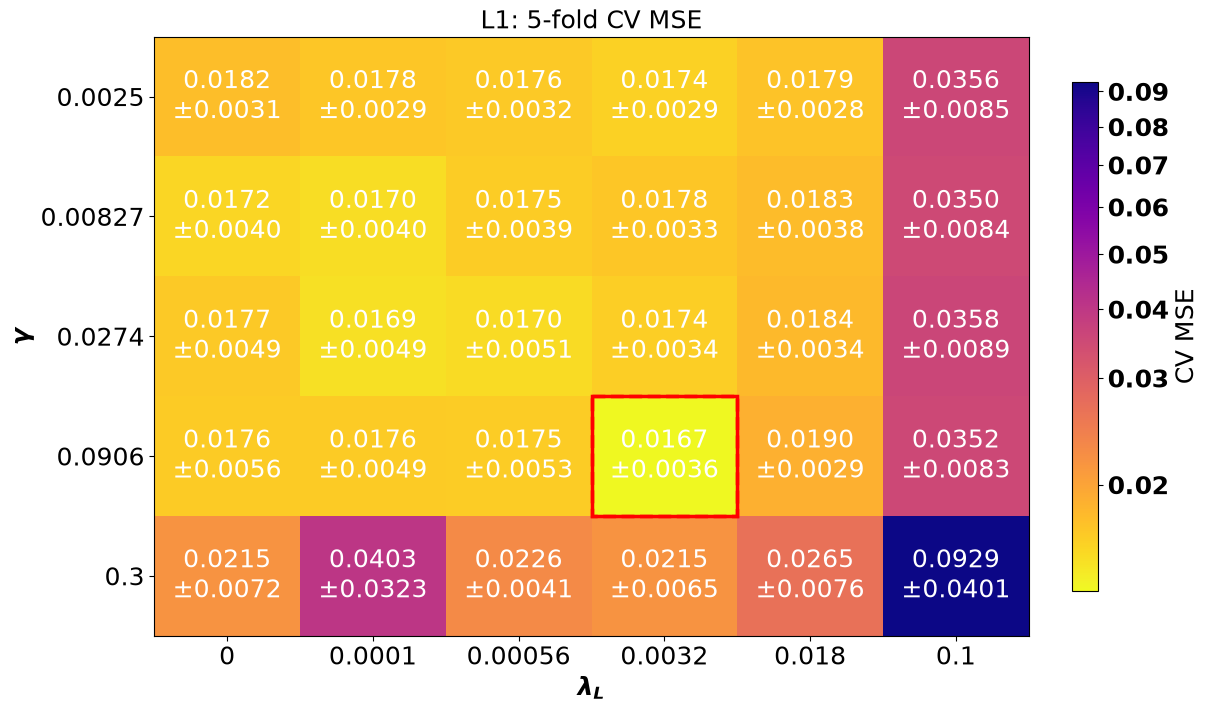

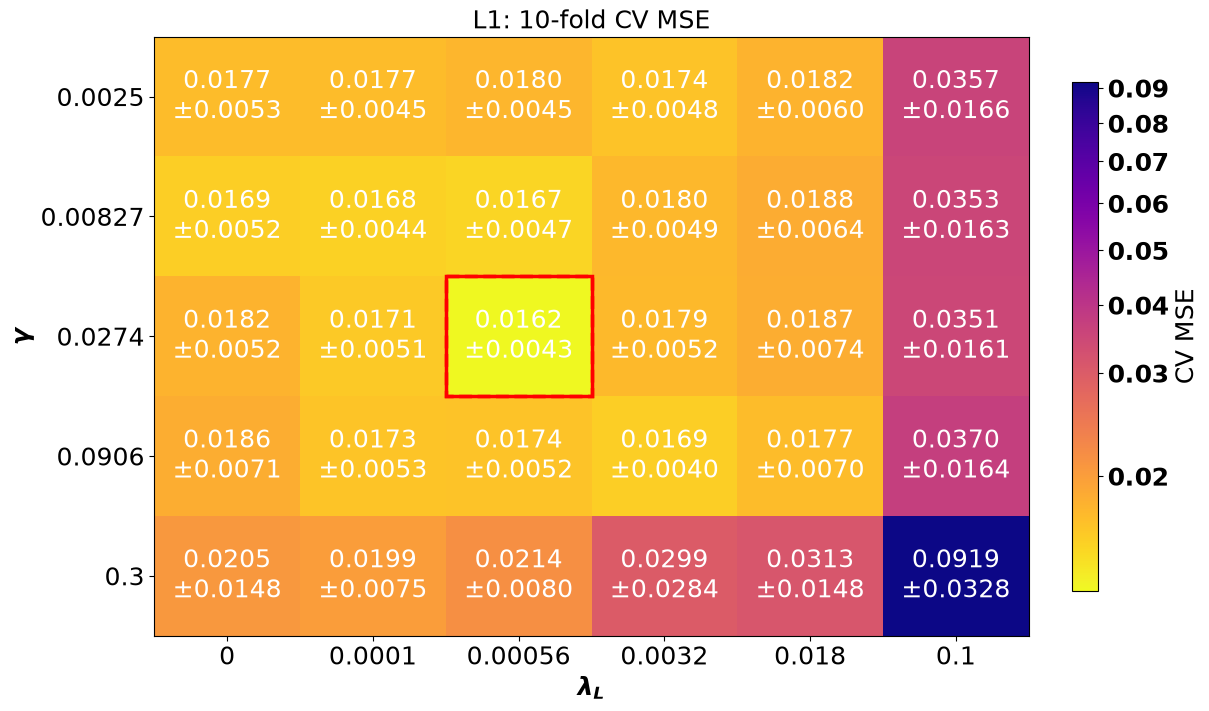

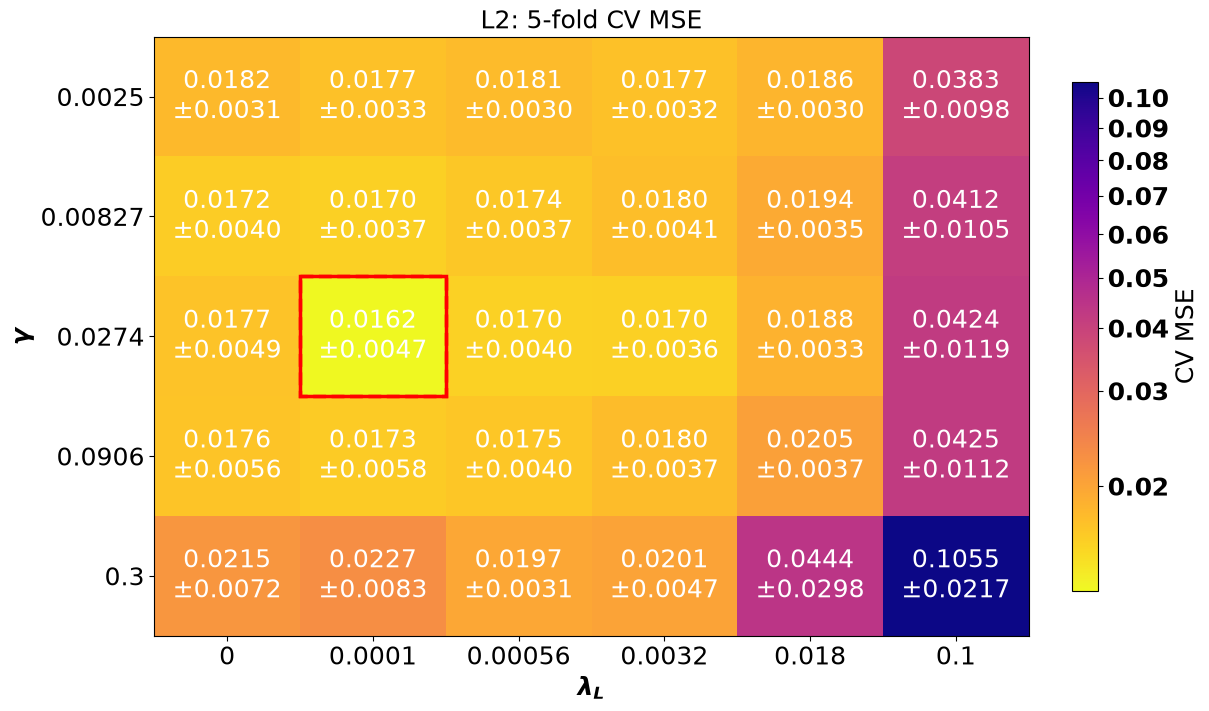

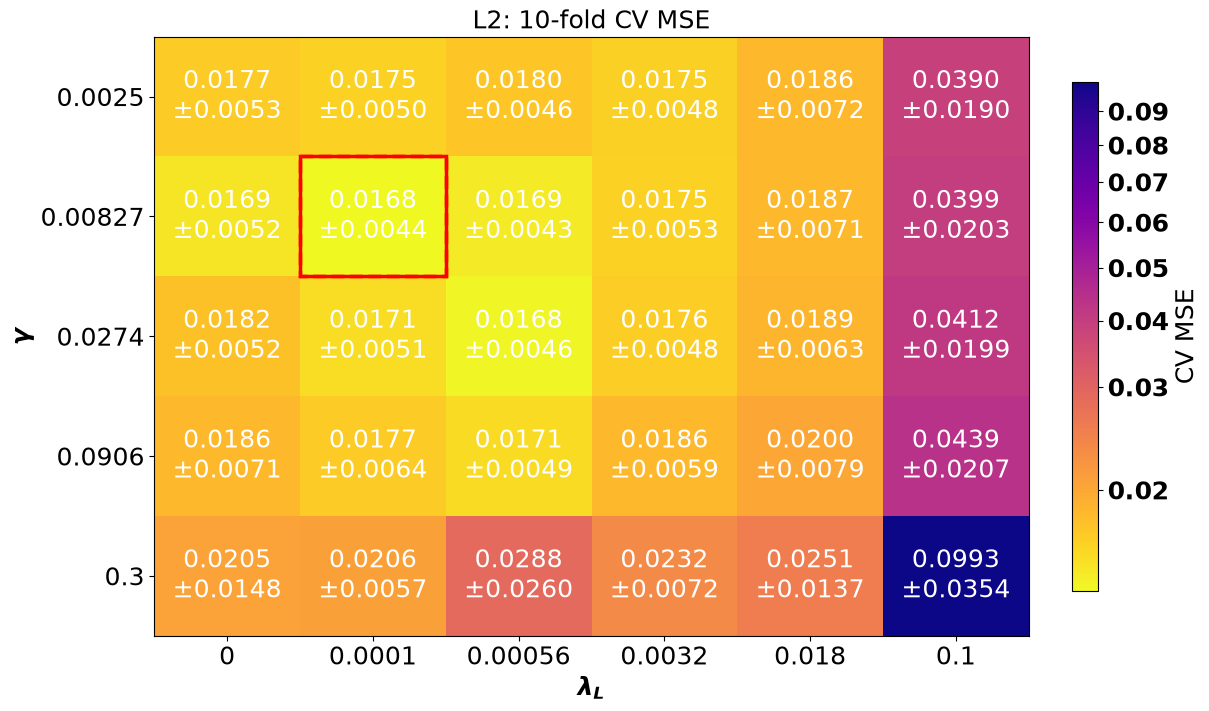

In [ ]:
from matplotlib.colors import PowerNorm #for the heatmap

def add_zero_lambda(grid, res_mse, col):
    """Prepend a lambda=0 column to a pivoted (gamma x lambda) grid,
    filled with the plain-MSE CV results (col = 'cv_mse' or 'cv_std')."""
    grid = grid.copy()
    grid.index = grid.index.astype(float)
    grid.columns = grid.columns.astype(float)

    mse_series = res_mse.set_index(
        res_mse['param_regressor__net__gamma'].astype(float)
    )[col]

    grid.insert(0, 0.0, mse_series.reindex(grid.index))
    grid.columns.name = 'param_lmbd'
    return grid


def build_grids(res_pen, res_mse):
    mse_grid = res_pen.pivot(index='param_gamma', columns='param_lmbd', values='cv_mse')
    std_grid = res_pen.pivot(index='param_gamma', columns='param_lmbd', values='cv_std')
    return (add_zero_lambda(mse_grid, res_mse, 'cv_mse'),
            add_zero_lambda(std_grid, res_mse, 'cv_std'))


# 5-fold: penalised grids + MSE from the 5-fold run
mse_grid_L1_5fold,  std_grid_L1_5fold  = build_grids(res_L1_5fold,  res_MSE_5fold)
mse_grid_L2_5fold,  std_grid_L2_5fold  = build_grids(res_L2_5fold,  res_MSE_5fold)

# 10-fold: penalised grids + MSE from the 10-fold run
mse_grid_L1_10fold, std_grid_L1_10fold = build_grids(res_L1_10fold, res_MSE_10fold)
mse_grid_L2_10fold, std_grid_L2_10fold = build_grids(res_L2_10fold, res_MSE_10fold)


def plot_results(mse_grid, std_grid, penalty, fold):
    ftsz = 18

    best = np.unravel_index(np.argmin(mse_grid.values), mse_grid.shape)

    nonzero_cols = np.where(mse_grid.columns.astype(float) != 0)[0]
    nonzero_grid = mse_grid.values[:, nonzero_cols]
    best_nonzero_local = np.unravel_index(np.argmin(nonzero_grid), nonzero_grid.shape)
    best_nonzero = (best_nonzero_local[0], nonzero_cols[best_nonzero_local[1]])

    fig, ax = plt.subplots(figsize=(12, 7), constrained_layout=True)

    im = ax.imshow(
        mse_grid.values,
        cmap='plasma_r',
        aspect='auto',
        norm=PowerNorm(
            gamma=0.5,
            vmin=np.nanmin(mse_grid.values),
            vmax=np.nanmax(mse_grid.values)
        )
    )

    for i in range(mse_grid.shape[0]):
        for j in range(mse_grid.shape[1]):
            ax.text(
                j, i,
                f"{mse_grid.values[i, j]:.4f}\n±{std_grid.values[i, j]:.4f}",
                ha='center', va='center',
                color='white', fontsize=ftsz, fontweight='normal'
            )

    ax.add_patch(plt.Rectangle(
        (best[1] - 0.5, best[0] - 0.5), 1, 1,
        fill=False, ec='red', lw=2.5
    ))

    ax.add_patch(plt.Rectangle(
        (best_nonzero[1] - 0.5, best_nonzero[0] - 0.5), 1, 1,
        fill=False, ec='red', lw=2.5, linestyle='--'
    ))

    ax.set_xticks(range(len(mse_grid.columns)))
    ax.set_xticklabels(
        [f"{v:.2g}" for v in mse_grid.columns],
        fontsize=ftsz, fontweight='normal'
    )

    ax.set_yticks(range(len(mse_grid.index)))
    ax.set_yticklabels(
        [f"{v:.3g}" for v in mse_grid.index],
        fontsize=ftsz, fontweight='normal'
    )

    ax.set_xlabel('$\\lambda_L$', fontsize=ftsz, fontweight='normal')
    ax.set_ylabel('$\\gamma$', fontsize=ftsz, fontweight='normal')
    ax.set_title(f'{penalty}: {fold}-fold CV MSE', fontsize=ftsz, fontweight='normal')

    cbar = fig.colorbar(im, ax=ax, shrink=0.85)
    cbar.ax.tick_params(labelsize=ftsz)
    cbar.set_label('CV MSE', fontsize=ftsz, fontweight='normal')

    plt.show()
    return fig


fig_L1_5fold  = plot_results(mse_grid_L1_5fold,  std_grid_L1_5fold,  'L1', 5)
fig_L1_10fold = plot_results(mse_grid_L1_10fold, std_grid_L1_10fold, 'L1', 10)
fig_L2_5fold  = plot_results(mse_grid_L2_5fold,  std_grid_L2_5fold,  'L2', 5)
fig_L2_10fold = plot_results(mse_grid_L2_10fold, std_grid_L2_10fold, 'L2', 10)

In [ ]:
# output_dir = Path("/Users/paula/machine_learning_uio/Projects/WorkingCopies/plots")

# fig_L1_5fold.savefig(output_dir / 'L1_5fold_CV.pdf', dpi=300, bbox_inches='tight')
# fig_L1_10fold.savefig(output_dir / 'L1_10fold_CV.pdf', dpi=300, bbox_inches='tight')
# fig_L2_5fold.savefig(output_dir / 'L2_5fold_CV.pdf', dpi=300, bbox_inches='tight')
# fig_L2_10fold.savefig(output_dir / 'L2_10fold_CV.pdf', dpi=300, bbox_inches='tight')

## solution part f) 

### Part f): Critical evaluation of the various algorithms

After all these glorious calculations, you should now summarize the various algorithms and come with a critical evaluation of their pros and cons. Which algorithm works best for the regression case and which is best for the classification case? Section [8.15](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#limitations-and-a-top-down-view) of the lecture notes gives a top-down view of what neural networks can and cannot do that you may find useful here. These codes can also be part of your final project 3, but now applied to other data sets.


This is done thoroughly in the report. 